# R01 · New data splits (review fix)

**Reviewer C:** "Sections 3 and 4 describe chronological 70/10/20 splits, whereas Figure 1 states that all
anomalous windows are assigned exclusively to the test set. What happens to anomalies in the original
training and validation periods?"

**What the old code did (notebooks 01/02):** joined all files, split only the *normal* rows by time, and
moved **every anomaly from every period** into the test set. So the test set mixed the *latest* normal data
with anomalies from *all* periods. This changes what the models are tested on, and it is the reason the
NAB test prevalence was 35.6%.

**What this notebook does instead:**

| | Old (submitted paper) | New (this revision) |
|---|---|---|
| Unit of splitting | all files joined | each file separately |
| Anomalies | all moved to test | stay where they happen; windows with anomalies are dropped from train/val/cal |
| Splits | train / val / test | train / val / **cal** / test |
| Calibration for conformal | val (also used for early stopping) | separate **cal** split, used for nothing else |
| Scaler | MinMax fitted on train | MinMax fitted per file on its train rows |

**SKAB:** every experiment file is ≈570 normal rows → one fault (≈400 rows) → a normal tail. The *normal
prefix* before the fault is split 60/10/10/20 (train/val/cal/test-head); the test split is the test-head
plus everything from the fault onward. `anomaly-free.csv` is split 60/10/10/20 by time.

**NAB:** each file split 40/10/10/40 by time (the table below shows why not 60/10/10/20).

In [1]:
# ── Settings ──────────────────────────────────────────────────────────────
import os
WORKERS = int(os.environ.get("REV_WORKERS", 8))   # training jobs side by side on the GPU
DEVICE  = None     # None = use the GPU if there is one
RESULTS = os.environ.get("REV_RESULTS", "results")
RUN     = True     # False = skip training, only rebuild tables/figures from results/

import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import report, plots
from scripts.run_jobs import run_stage, stage_tags
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
os.makedirs("tables_rev", exist_ok=True)

def export(df, name):
    """Save a table as tables_rev/REV_<name>.csv and show it."""
    path = f"tables_rev/REV_{name}.csv"; df.to_csv(path); display(df); print("saved", path)

In [2]:
from src.data import get_data, summary, load_nab
data = {ds: get_data(ds, rebuild=True) for ds in ("SKAB", "NAB")}
summ = {ds: summary(d) for ds, d in data.items()}
for ds, s in summ.items():
    display(Markdown(f"**{ds}** (W={data[ds]['window_size']})")); display(s)

**SKAB** (W=30)

,split,windows,anomalous,prevalence,files
0,train,16071,0,0.0000,35
1,val,1850,0,0.0000,34
2,cal,1854,0,0.0000,34
3,test,23008,13987,0.6079,35


**NAB** (W=50)

,split,windows,anomalous,prevalence,files
0,train,130372,0,0.0000,58
1,val,29820,0,0.0000,58
2,cal,29753,0,0.0000,57
3,test,143385,17133,0.1195,58


### Old vs new split sizes
Old numbers are the ones printed in Section 3 of the submitted paper.

In [3]:
old = {"SKAB": dict(train=23588, val=3345, cal=0, test=19786, test_anom=13357),
       "NAB":  dict(train=229577, val=30354, cal=0, test=97101, test_anom=34579)}
rows = []
for ds in ("SKAB", "NAB"):
    s = summ[ds].set_index("split")
    new = dict(train=s.loc["train","windows"], val=s.loc["val","windows"], cal=s.loc["cal","windows"],
               test=s.loc["test","windows"], test_anom=s.loc["test","anomalous"])
    for tag, v in (("old", old[ds]), ("new", new)):
        rows.append({"dataset": ds, "protocol": tag, **v, "test_prevalence": round(v["test_anom"]/v["test"], 3)})
export(pd.DataFrame(rows).set_index(["dataset","protocol"]), "split_old_vs_new")

train    val    cal    test  test_anom  test_prevalence
dataset protocol                                                          
SKAB    old        23588   3345      0   19786      13357            0.675
        new        16071   1850   1854   23008      13987            0.608
NAB     old       229577  30354      0   97101      34579            0.356
        new       130372  29820  29753  143385      17133            0.119

saved tables_rev/REV_split_old_vs_new.csv


### Why NAB uses 40/10/10/40 and not 60/10/10/20
NAB anomalies are spread over the whole series. With a 60/10/10/20 cut, most labelled anomalies fall in the
training period (where their windows are dropped) and many files have no anomaly in test at all.

In [4]:
opts = []
for r in [(0.6,0.1,0.1,0.2), (0.5,0.1,0.1,0.3), (0.4,0.1,0.1,0.4)]:
    d = load_nab(ratios=r)
    ft = pd.Series(d["y_test"]).groupby(d["file_test"]).max()
    opts.append({"ratios": "/".join(str(int(x*100)) for x in r), "test windows": len(d["y_test"]),
                 "test prevalence": round(d["y_test"].mean(), 3),
                 "files with a test anomaly": f"{int(ft.sum())}/{len(ft)}"})
export(pd.DataFrame(opts).set_index("ratios"), "nab_split_options")

,test windows,test prevalence,files with a test anomaly
ratios,,,
60/10/10/20,70260,0.115,18/58
50/10/10/30,106837,0.124,32/58
40/10/10/40,143385,0.119,41/58


saved tables_rev/REV_nab_split_options.csv


### Per-file view (SKAB)
Every file contributes train/val/cal windows from its own normal prefix, and its own fault to test.

In [5]:
d = data["SKAB"]
pf = pd.DataFrame({s: pd.Series(d[f"file_{s}"]).value_counts() for s in ("train","val","cal","test")}).fillna(0).astype(int)
pf["test anomalous"] = pd.Series(d["y_test"]).groupby(d["file_test"]).sum()
display(pf.sort_index())

,train,val,cal,test,test anomalous
anomaly-free/anomaly-free.csv,5614,912,911,1852,0
other/1.csv,305,27,27,270,188
other/10.csv,313,28,28,842,615
other/11.csv,313,28,28,705,480
other/12.csv,312,28,27,565,338
other/13.csv,268,20,21,498,294
other/14.csv,314,28,28,419,331
other/2.csv,33,0,0,668,405
other/3.csv,312,28,27,654,427
other/4.csv,449,50,51,525,395


### New Figure 1 (replaces the old split figure)

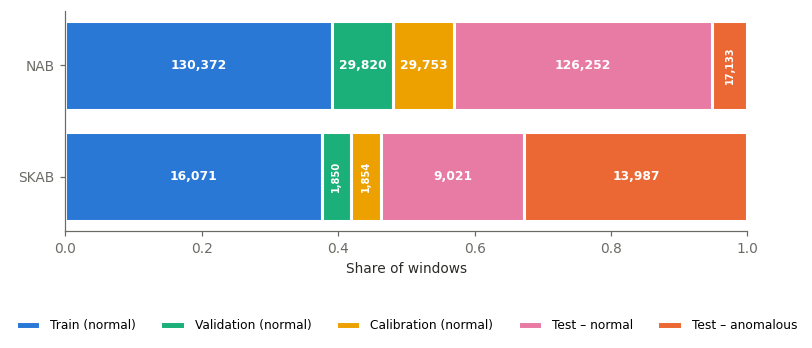

saved figures_rev/REV_fig1_split_composition.png


In [6]:
fig, path = plots.split_composition(summ); plt.show(); print("saved", path)

### Checks

In [7]:
from src.data import check
for ds, d in data.items():
    check(d)                                   # no anomalous window in train/val/cal, nothing empty
    assert set(d["file_cal"]) <= set(d["file_train"]) | set(d["file_val"]) | set(d["file_test"])
print("all split checks passed")

all split checks passed
